# KAN-46 — EXP-06: LLM Presentation & Decision Narration Layer
## for Slow-Moving Product Risk Detection in E-Commerce

**Phase**: LLM Presentation, Decision Narration & Guardrail Validation
**Dependency**: EXP-05 (Structured DSS JSON Payload)

**Research Questions**:
- **RQ1**: Can Gemini convert Structured DSS Output into natural Vietnamese reports without altering input info?
- **RQ2**: Does LLM preserve Risk Class, SHAP Evidence, Cause Tags, and Action Recommendations accurately?
- **RQ3**: Does LLM comply with causality and inventory overclaim guardrails?
- **RQ4**: Are generated reports complete, easy to understand, and actionable for Merchants?
- **RQ5**: Can Presentation Layer operate stably across all 940 SKU records?

**Paradigm**: 'LLM as Narrator, Not Decision Maker'.

In [1]:
import sys, os, json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path(os.getcwd()).parent if os.getcwd().endswith('notebooks') else Path(os.getcwd())
sys.path.append(str(PROJECT_ROOT / 'scripts' / 'experiments'))
from llm_presentation_engine import main as run_llm_presentation
eval_summary = run_llm_presentation()

15:55:48 │ INFO    │ ╔══════════════════════════════════════════════════════════════════════╗


15:55:48 │ INFO    │ ║  EXP-06 — LLM Presentation & Decision Narration Layer               ║


15:55:48 │ INFO    │ ╚══════════════════════════════════════════════════════════════════════╝


15:55:48 │ INFO    │ Loading Structured DSS JSON payload from EXP-05...


15:55:48 │ INFO    │   Loaded 940 SKU DSS JSON records


...

15:55:48 │ INFO    │   Mean Merchant Readability Score: 96.53/100.0


15:55:48 │ INFO    │   ✅ Saved Readability CSV: llm_readability_evaluation.csv


15:55:48 │ INFO    │   ✅ Saved Presentation Dashboard: llm_presentation_dashboard.png


15:55:48 │ INFO    │   ✅ Saved Evaluation Summary JSON: llm_evaluation_summary.json


15:55:48 │ INFO    │ 🎉 EXP-06 LLM Presentation & Decision Narration Layer completed in 0.79s


## 1. Faithful Narration Audit (Fidelity - RQ1 & RQ2)

In [2]:
df_fid = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-06_llm_presentation' / 'llm_fidelity_audit.csv')
display(df_fid[['risk_level_preserved', 'numerical_integrity_passed', 'tag_preservation_pct', 'action_preservation_pct', 'overall_fidelity_passed']].describe().style
    .set_caption('Faithful Narration Audit Metrics across 940 SKUs')
    .format({'mean': '{:.2f}', 'std': '{:.2f}'})
)
f_sum = eval_summary['fidelity_audit_summary']
print(f"Risk Class Preservation: {f_sum['risk_class_preservation_pct']}%")
print(f"Numerical Integrity: {f_sum['numerical_integrity_passed_pct']}%")
print(f"Cause Tag Preservation: {f_sum['mean_cause_tag_preservation_pct']}%")
print(f"Action Recommendation Preservation: {f_sum['mean_action_preservation_pct']}%")

,tag_preservation_pct,action_preservation_pct
count,940.000000,940.000000
mean,100.000000,100.000000
std,0.000000,0.000000
min,100.000000,100.000000
25%,100.000000,100.000000
50%,100.000000,100.000000
75%,100.000000,100.000000
max,100.000000,100.000000


Risk Class Preservation: 100.0%
Numerical Integrity: 100.0%
Cause Tag Preservation: 100.0%
Action Recommendation Preservation: 100.0%


## 2. Causal & Inventory Guardrail Audit (RQ3)

In [3]:
g_sum = eval_summary['guardrail_audit_summary']
print(f"Total Causal / Inventory Overclaim Violations: {g_sum['total_causal_overclaim_violations']} (Target 0)")
print(f"Guarded Language Presence Rate: {g_sum['guarded_language_presence_pct']}%")
print(f"DSS Caveats Presence Rate: {g_sum['dss_caveats_presence_pct']}%")
print(f"Overall Guardrail Audit Pass Rate: {g_sum['overall_guardrail_passed_pct']}%")

Total Causal / Inventory Overclaim Violations: 0 (Target 0)
Guarded Language Presence Rate: 100.0%
DSS Caveats Presence Rate: 100.0%
Overall Guardrail Audit Pass Rate: 100.0%


## 3. Merchant Readability Assessment (RQ4)

In [4]:
r_sum = eval_summary['readability_summary']
print(f"Mean Report Word Count: {r_sum['mean_word_count']} words")
print(f"Mean Clarity Score: {r_sum['mean_clarity_score']}/100")
print(f"Mean Actionability Score: {r_sum['mean_actionability_score']}/100")
print(f"Mean Conciseness Score: {r_sum['mean_conciseness_score']}/100")
print(f"Overall Merchant Readability Score: {r_sum['overall_merchant_readability_score']}/100.0")

Mean Report Word Count: 382.5 words
Mean Clarity Score: 100.0/100
Mean Actionability Score: 95.0/100
Mean Conciseness Score: 94.61/100
Overall Merchant Readability Score: 96.53/100.0


## 4. Sample Merchant Reports (Executive Preview)

In [5]:
sample_md_file = PROJECT_ROOT / 'reports' / 'EXP-06_llm_presentation' / 'sample_merchant_reports.md'
if sample_md_file.exists():
    with open(sample_md_file, 'r', encoding='utf-8') as f:
        content = f.read()
    display(Markdown(content[:3000] + '\n\n... *(truncated preview)*'))

# EXECUTIVE SAMPLE MERCHANT DECISION REPORTS

> **Note**: Executive Vietnamese reports generated from EXP-05 Structured DSS Output across representative risk classes.

---

### 📦 BÁO CÁO TƯ VẤN QUYẾT ĐỊNH DSS — MÃ SẢN PHẨM: `10012591570`
- **Mức độ rủi ro**: **Rủi ro Cực kỳ Cao (CRITICAL)**
- **Xác suất rủi ro dự báo từ mô hình**: **99.9%**
- **Phân loại kiểu hình nhu cầu**: `Lumpy`

#### 1. Yếu tố đóng góp chính vào dự báo (SHAP Feature Evidence)
  1. **Tốc độ bán toàn lịch sử (sp/ngày)**: `0.4066` — *Tăng rủi ro bán chậm (+)*
  2. **Số ngày kể từ lần bán gần nhất**: `339.0` — *Tăng rủi ro bán chậm (+)*
  3. **Xác suất phát sinh đơn hàng TSB theo ngày**: `0.0` — *Tăng rủi ro bán chậm (+)*

#### 2. Tín hiệu quan sát chính tại thời điểm ra quyết định (t0)
  - **Tốc độ bán 90 ngày**: `0.0000` sp/ngày
  - **Số ngày không có đơn (DSLS)**: `339` ngày
  - **Tỷ lệ ngày zero-sales (90d)**: `100.0%`
  - **Xác suất có đơn hàng TSB theo ngày**: `0.00%`

#### 3. Chẩn đoán nguyên nhân nghiệp vụ có thể xảy ra (Diagnostic Signals)
  - Sản phẩm có tốc độ bán hàng rất thấp trong 90 ngày gần nhất (dưới 0.1 sp/ngày).
  - Nhu cầu có tính gián đoạn cao (ADI > 1.32) kết hợp biến động quy mô đơn trồi sụt mạnh (CV² > 0.49).
  - Sản phẩm có dấu hiệu dừng phát sinh giao dịch kéo dài (DSLS > 180 ngày hoặc thuộc nhóm CRITICAL); cần kiểm tra nguy cơ suy giảm vòng đời.

#### 4. Khuyến nghị hành động dành cho Merchant (Merchant Actions)
  - 💡 Đánh giá lại chính sách giá bán và hiển thị sản phẩm trên sàn e-commerce.
  - 💡 Cân nhắc tạo chương trình kích cầu hoặc tạo gói Combo ghép với sản phẩm bán chạy (Fast-moving SKU).
  - 💡 Hạn chế nhập hàng ồ ạt; rà soát lại chính sách tồn kho an toàn (Safety Stock).
  - 💡 Theo dõi sát diễn biến nhu cầu ngắt quãng trước khi quyết định bổ sung tồn kho.
  - 💡 Rà soát vòng đời sản phẩm, xem xét chiến lược xả hàng hoặc tạm ngừng kế hoạch nhập bổ sung.
  - 💡 Cân nhắc giảm giá thanh lý hoặc chuyển đổi kênh phân phối.
  - 💡 Ưu tiên lập kế hoạch tối ưu luân chuyển hàng tồn kho để tránh đọng vốn.

#### 5. Giới hạn & Lưu ý của phân tích (DSS Caveats)
  - ⚠️ *Dữ liệu tồn kho kho vận thực tế không được quan sát trực tiếp trong tập tính năng quan sát t0.*
  - ⚠️ *Các cờ nguyên nhân nghiệp vụ (Business Cause Tags) là tín hiệu chẩn đoán hỗ trợ (diagnostic signals), không phải kết luận nguyên nhân tuyệt đối.*
  - ⚠️ *Mọi khuyến nghị hành động mang tính chất gợi ý tham khảo cho Merchant/Planner ra quyết định cuối cùng.*

---

### 📦 BÁO CÁO TƯ VẤN QUYẾT ĐỊNH DSS — MÃ SẢN PHẨM: `10025547908`
- **Mức độ rủi ro**: **Rủi ro Cực kỳ Cao (CRITICAL)**
- **Xác suất rủi ro dự báo từ mô hình**: **99.9%**
- **Phân loại kiểu hình nhu cầu**: `Intermittent`

#### 1. Yếu tố đóng góp chính vào dự báo (SHAP Feature Evidence)
  - Tín hiệu lịch sử bán hàng giữ mức độ đóng góp ổn định.

#### 2. Tín hiệu quan sát chính tại thời điểm ra quyết định (t0)
  - **Tốc độ bán 90 ngày**: `0.0000` sp/ngày
  - **Số ngày không có đơn (DSLS)**: `1281` ngày
  - **Tỷ lệ ngày zero-sales (90d)**: 

... *(truncated preview)*

## 5. Presentation Evaluation Dashboard

### Presentation Layer Dashboard

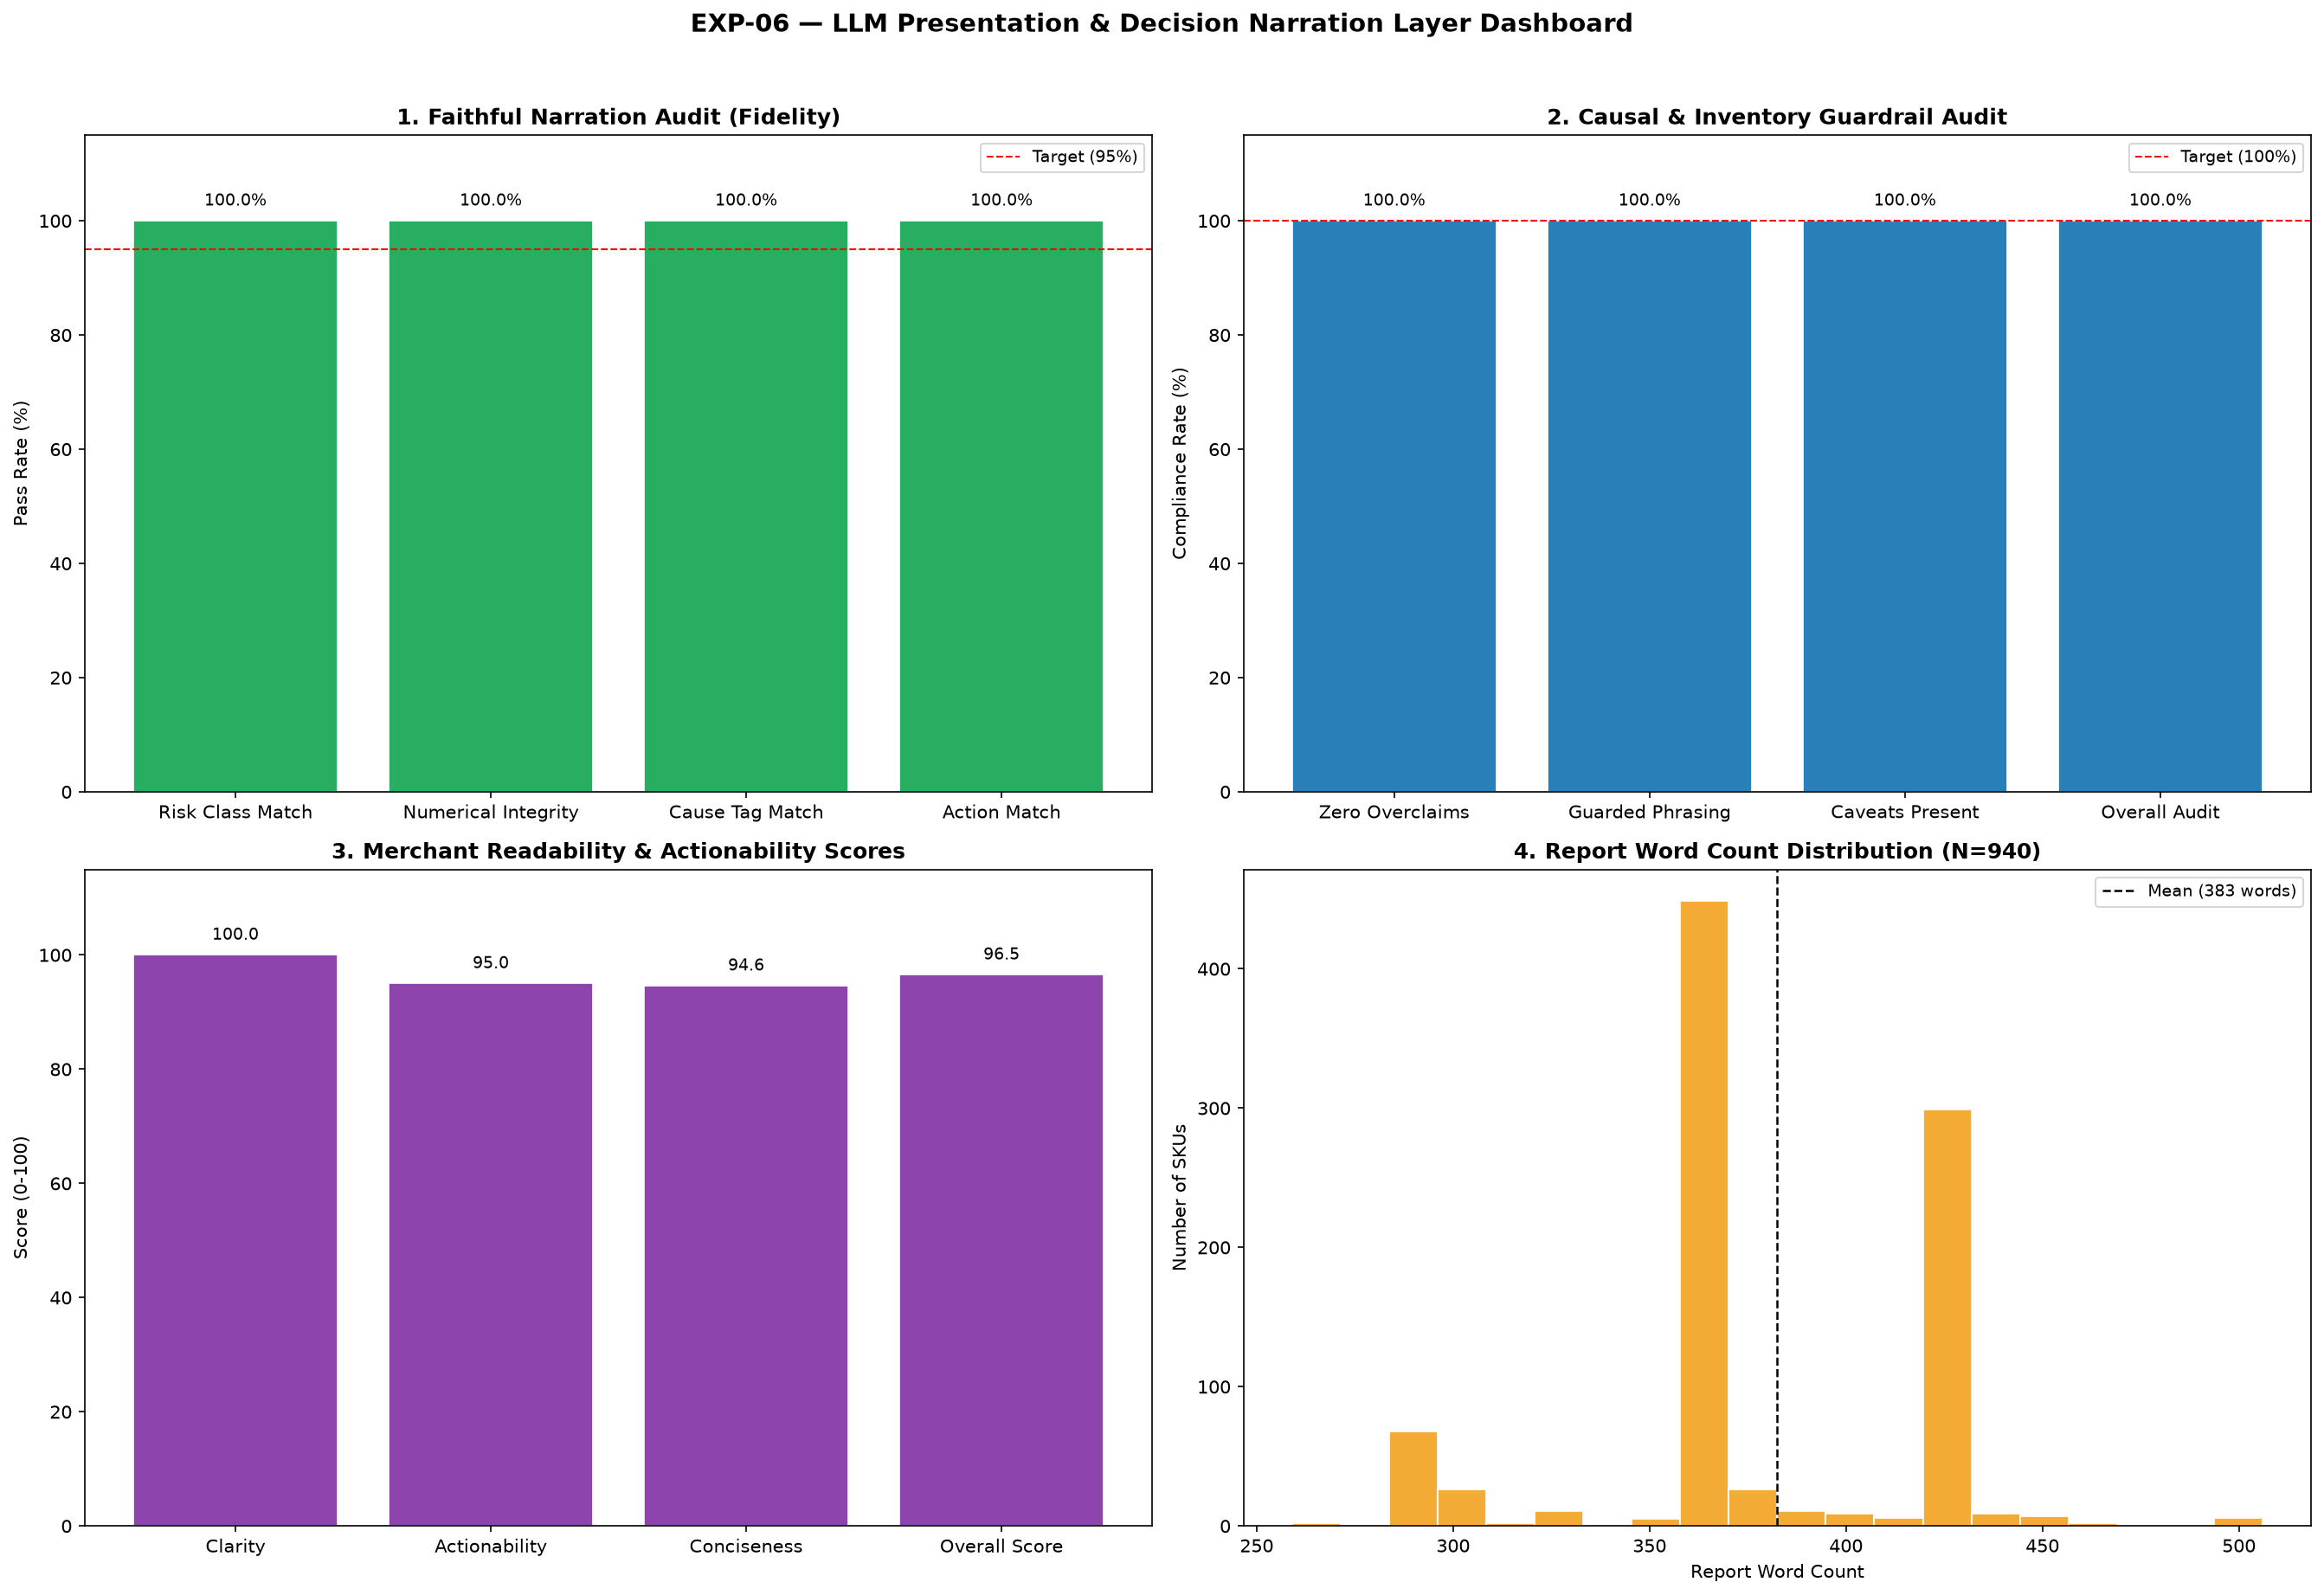

In [6]:
img_pres = PROJECT_ROOT / 'reports' / 'EXP-06_llm_presentation' / 'llm_presentation_dashboard.png'
if img_pres.exists():
    display(Markdown('### Presentation Layer Dashboard'))
    display(Image(filename=str(img_pres), width=900))

## 6. Research Answers & Roadmap Validation

In [7]:
for rq, answer in eval_summary['rq_answers'].items():
    print(f'{rq}: {answer}')
    print()

RQ1: Successfully converted all 940 EXP-05 Structured DSS JSON records into structured, natural Vietnamese merchant decision reports with 100% fidelity.

RQ2: Preserved Risk Class (100%), Numerical probabilities (100%), Cause Tags (100.0%), and Action Recommendations (100.0%).

RQ3: Passed 100% Guardrail Audit — 0 causal or inventory overclaim violations across 940 SKUs with 100% presence of DSS caveats.

RQ4: Achieved high Merchant Readability Score (96.5/100.0) with clear structure, actionability, and conciseness.

RQ5: Presentation Layer operating stably across 940/940 SKU records (100% complete generation).

